In [1]:
import pandas as pd
import numpy as np
import scipy
import statsmodels
import sqlalchemy

print("Python environment is ready!")

Python environment is ready!


In [2]:
from pathlib import Path
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

current_folder = Path.cwd()
project_root = current_folder.parent if current_folder.name == "notebooks" else current_folder
load_dotenv(project_root / ".env")

required_variables = ["DB_USER", "DB_PASSWORD", "DB_HOST", "DB_PORT", "DB_NAME"]
missing_variables = [name for name in required_variables if not os.getenv(name)]
engine = None
database_available = False

if not missing_variables:
    try:
        database_url = URL.create(
            drivername="postgresql+psycopg2",
            username=os.getenv("DB_USER"),
            password=os.getenv("DB_PASSWORD"),
            host=os.getenv("DB_HOST"),
            port=int(os.getenv("DB_PORT")),
            database=os.getenv("DB_NAME"),
        )
        candidate_engine = create_engine(database_url, pool_pre_ping=True)
        with candidate_engine.connect() as connection:
            current_database = connection.execute(
                text("SELECT current_database();")
            ).scalar_one()
        engine = candidate_engine
        database_available = True
        print(f"PostgreSQL available: {current_database}")
    except Exception as exc:
        print(f"PostgreSQL unavailable ({type(exc).__name__}); trying local CSV.")
else:
    print(f"Database settings missing: {missing_variables}; trying local CSV.")


PostgreSQL available: cookie_cats_ab


In [3]:
if database_available:
    with engine.connect() as connection:
        current_database = connection.execute(
            text("SELECT current_database();")
        ).scalar_one()
        total_players = connection.execute(
            text("SELECT COUNT(*) FROM raw.cookie_cats;")
        ).scalar_one()
    print(f"Connected database: {current_database}")
    print(f"Players found in raw table: {total_players:,}")
else:
    csv_path = project_root / "data" / "raw" / "cookie_cats.csv"
    if not csv_path.exists():
        raise FileNotFoundError(
            "Neither PostgreSQL nor the local CSV is available. Configure .env "
            "and load PostgreSQL, or place the dataset at " + str(csv_path)
        )
    print(f"Using local CSV fallback: {csv_path}")


Connected database: cookie_cats_ab
Players found in raw table: 90,189


In [4]:
if database_available:
    query = """
    SELECT userid, version, experiment_group, sum_gamerounds,
           retention_1, retention_7, retention_1_flag, retention_7_flag,
           is_zero_round_player, is_extreme_outlier
    FROM analytics.cookie_cats_analysis;
    """
    df = pd.read_sql(query, engine)
else:
    df = pd.read_csv(csv_path)
    required_columns = {
        "userid", "version", "sum_gamerounds", "retention_1", "retention_7"
    }
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(f"CSV is missing required columns: {sorted(missing_columns)}")
    df["experiment_group"] = df["version"]
    df["retention_1_flag"] = df["retention_1"].astype(int)
    df["retention_7_flag"] = df["retention_7"].astype(int)
    df["is_zero_round_player"] = df["sum_gamerounds"].eq(0)
    df["is_extreme_outlier"] = df["sum_gamerounds"].eq(df["sum_gamerounds"].max())

print(f"Rows loaded: {len(df):,}")
print(f"Columns loaded: {df.shape[1]}")
df.head()


Rows loaded: 90,189
Columns loaded: 10


,userid,version,experiment_group,sum_gamerounds,retention_1,retention_7,retention_1_flag,retention_7_flag,is_zero_round_player,is_extreme_outlier
0,116,gate_30,Control,3,False,False,0,0,False,False
1,337,gate_30,Control,38,True,False,1,0,False,False
2,377,gate_40,Treatment,165,True,False,1,0,False,False
3,483,gate_40,Treatment,1,False,False,0,0,False,False
4,488,gate_40,Treatment,179,True,True,1,1,False,False


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   userid                90189 non-null  int64 
 1   version               90189 non-null  object
 2   experiment_group      90189 non-null  object
 3   sum_gamerounds        90189 non-null  int64 
 4   retention_1           90189 non-null  bool  
 5   retention_7           90189 non-null  bool  
 6   retention_1_flag      90189 non-null  int64 
 7   retention_7_flag      90189 non-null  int64 
 8   is_zero_round_player  90189 non-null  bool  
 9   is_extreme_outlier    90189 non-null  bool  
dtypes: bool(4), int64(4), object(2)
memory usage: 4.5+ MB


In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
userid,90189.0,NaN,NaN,NaN,4998412.234496,2883285.6077,116.0,2512230.0,4995815.0,7496452.0,9999861.0
version,90189,2,gate_40,45489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experiment_group,90189,2,Treatment,45489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sum_gamerounds,90189.0,NaN,NaN,NaN,51.872457,195.050858,0.0,5.0,16.0,51.0,49854.0
retention_1,90189,2,False,50036,NaN,NaN,NaN,NaN,NaN,NaN,NaN
retention_7,90189,2,False,73408,NaN,NaN,NaN,NaN,NaN,NaN,NaN
retention_1_flag,90189.0,NaN,NaN,NaN,0.44521,0.496992,0.0,0.0,0.0,1.0,1.0
retention_7_flag,90189.0,NaN,NaN,NaN,0.186065,0.389161,0.0,0.0,0.0,0.0,1.0
is_zero_round_player,90189,2,False,86195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_extreme_outlier,90189,2,False,90188,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df["version"].value_counts()

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

In [8]:
quality_summary = pd.Series({
    "total_rows": len(df),
    "unique_users": df["userid"].nunique(),
    "duplicate_userids": df["userid"].duplicated().sum(),
    "total_missing_values": df.isna().sum().sum(),
    "negative_round_records": (df["sum_gamerounds"] < 0).sum(),
    "zero_round_players": (df["sum_gamerounds"] == 0).sum(),
    "extreme_outliers_flagged": df["is_extreme_outlier"].sum()
})

quality_summary.to_frame(name="value")

,value
total_rows,90189
unique_users,90189
duplicate_userids,0
total_missing_values,0
negative_round_records,0
zero_round_players,3994
extreme_outliers_flagged,1


In [9]:
expected_checks = {
    "Expected dataset size": len(df) == 90189,
    "Every user is unique": df["userid"].nunique() == len(df),
    "No duplicate user IDs": df["userid"].duplicated().sum() == 0,
    "No missing values": df.isna().sum().sum() == 0,
    "No negative game rounds": (df["sum_gamerounds"] < 0).sum() == 0,
    "Both expected experiment groups present": set(df["version"].unique()) == {"gate_30", "gate_40"},
}
for check_name, passed in expected_checks.items():
    assert passed, f"Data quality check failed: {check_name}"
print("All core data-quality assertions passed.")


All core data-quality assertions passed.


## Experiment Validity: Sample Ratio Mismatch Test

Before analysing experiment outcomes, we test whether users were allocated
approximately according to the intended 50/50 split.

- Null hypothesis: Users were allocated 50% to each experiment group.
- Alternative hypothesis: The allocation differs from 50/50.
- Significance level: 0.05

In [10]:
from scipy.stats import chisquare


# Keep the groups in a deliberate and readable order
observed_counts = (
    df["version"]
    .value_counts()
    .reindex(["gate_30", "gate_40"])
)

total_players = observed_counts.sum()

# Under a 50/50 experiment, each group should receive half the users
expected_counts = np.array([
    total_players / 2,
    total_players / 2
])

chi_square_stat, srm_p_value = chisquare(
    f_obs=observed_counts.values,
    f_exp=expected_counts
)

allocation_summary = pd.DataFrame({
    "version": observed_counts.index,
    "observed_players": observed_counts.values,
    "expected_players": expected_counts,
    "observed_percentage": (
        observed_counts.values / total_players * 100
    )
})

display(allocation_summary)

print(f"Chi-square statistic: {chi_square_stat:.4f}")
print(f"SRM p-value: {srm_p_value:.4f}")

,version,observed_players,expected_players,observed_percentage
0,gate_30,44700,45094.5,49.562585
1,gate_40,45489,45094.5,50.437415


Chi-square statistic: 6.9024
SRM p-value: 0.0086


In [11]:
alpha = 0.05

if srm_p_value < alpha:
    print(
        "SRM ALERT: The allocation differs significantly "
        "from the assumed 50/50 split."
    )
else:
    print(
        "PASS: There is no statistically significant evidence "
        "of a sample ratio mismatch."
    )

SRM ALERT: The allocation differs significantly from the assumed 50/50 split.


## Retention Hypothesis Testing

A two-proportion z-test is used to compare retention between the treatment
and control groups.

### Null hypothesis

The treatment and control groups have equal retention rates.

### Alternative hypothesis

The treatment and control groups have different retention rates.

- Significance level: 0.05
- Test type: Two-sided
- Primary metric: Day 7 retention
- Secondary metric: Day 1 retention

In [12]:
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest


def run_retention_test(data, metric, metric_name):
    """
    Compare a binary retention metric between gate_40 and gate_30.

    Treatment effect is calculated as:
    treatment rate minus control rate.
    """

    group_summary = (
        data.groupby("version")[metric]
        .agg(["sum", "count"])
    )

    control_successes = int(
        group_summary.loc["gate_30", "sum"]
    )
    control_users = int(
        group_summary.loc["gate_30", "count"]
    )

    treatment_successes = int(
        group_summary.loc["gate_40", "sum"]
    )
    treatment_users = int(
        group_summary.loc["gate_40", "count"]
    )

    # Treatment is placed first so a negative result means
    # the treatment performed worse than the control.
    successes = np.array([
        treatment_successes,
        control_successes
    ])

    observations = np.array([
        treatment_users,
        control_users
    ])

    z_statistic, p_value = proportions_ztest(
        count=successes,
        nobs=observations,
        alternative="two-sided"
    )

    control_rate = control_successes / control_users
    treatment_rate = treatment_successes / treatment_users

    absolute_effect = treatment_rate - control_rate

    # Standard error for the confidence interval
    standard_error = np.sqrt(
        treatment_rate * (1 - treatment_rate) / treatment_users
        +
        control_rate * (1 - control_rate) / control_users
    )

    critical_value = norm.ppf(0.975)

    confidence_interval_low = (
        absolute_effect - critical_value * standard_error
    )

    confidence_interval_high = (
        absolute_effect + critical_value * standard_error
    )

    return {
        "metric": metric_name,
        "control_users": control_users,
        "treatment_users": treatment_users,
        "control_retained": control_successes,
        "treatment_retained": treatment_successes,
        "control_rate_pct": control_rate * 100,
        "treatment_rate_pct": treatment_rate * 100,
        "absolute_effect_pp": absolute_effect * 100,
        "ci_95_low_pp": confidence_interval_low * 100,
        "ci_95_high_pp": confidence_interval_high * 100,
        "z_statistic": z_statistic,
        "p_value": p_value
    }

In [13]:
day_1_test = run_retention_test(
    data=df,
    metric="retention_1_flag",
    metric_name="Day 1 Retention"
)

day_7_test = run_retention_test(
    data=df,
    metric="retention_7_flag",
    metric_name="Day 7 Retention"
)

retention_test_results = pd.DataFrame([
    day_1_test,
    day_7_test
])

columns_to_display = [
    "metric",
    "control_rate_pct",
    "treatment_rate_pct",
    "absolute_effect_pp",
    "ci_95_low_pp",
    "ci_95_high_pp",
    "z_statistic",
    "p_value"
]

retention_test_results[columns_to_display].round(4)

,metric,control_rate_pct,treatment_rate_pct,absolute_effect_pp,ci_95_low_pp,ci_95_high_pp,z_statistic,p_value
0,Day 1 Retention,44.8188,44.2283,-0.5905,-1.2392,0.0582,-1.7841,0.0744
1,Day 7 Retention,19.0201,18.2000,-0.8201,-1.3282,-0.3121,-3.1644,0.0016


In [14]:
alpha = 0.05

for result in [day_1_test, day_7_test]:
    metric = result["metric"]
    effect = result["absolute_effect_pp"]
    p_value = result["p_value"]
    ci_low = result["ci_95_low_pp"]
    ci_high = result["ci_95_high_pp"]

    print(f"\n{metric}")
    print(f"Treatment effect: {effect:.2f} percentage points")
    print(f"95% confidence interval: [{ci_low:.2f}, {ci_high:.2f}]")
    print(f"P-value: {p_value:.4f}")

    if p_value < alpha:
        print(
            "Decision: Reject the null hypothesis. "
            "The difference is statistically significant."
        )
    else:
        print(
            "Decision: Fail to reject the null hypothesis. "
            "The evidence is not statistically significant."
        )


Day 1 Retention
Treatment effect: -0.59 percentage points
95% confidence interval: [-1.24, 0.06]
P-value: 0.0744
Decision: Fail to reject the null hypothesis. The evidence is not statistically significant.

Day 7 Retention
Treatment effect: -0.82 percentage points
95% confidence interval: [-1.33, -0.31]
P-value: 0.0016
Decision: Reject the null hypothesis. The difference is statistically significant.


## Engagement Analysis\n
\n
Total game rounds are analysed as a secondary experiment metric. The raw dataset contains an extreme observation of 49,854 rounds. The original analysis excludes the maximum observation from the primary engagement comparison, while retaining it in the raw data. A sensitivity analysis below compares results with all rows, with that exclusion rule, and with winsorization at the 99.9th percentile.\n
\n
Zero-round players remain included because they were valid experiment participants.\n
\n
Because game rounds are strongly skewed, the analysis uses means, medians, quartiles, a two-sided Mann–Whitney U test, and a rank-biserial effect size.

In [15]:
engagement_df = df.loc[
    ~df["is_extreme_outlier"]
].copy()

print(f"Original rows: {len(df):,}")
print(f"Engagement-analysis rows: {len(engagement_df):,}")
print(f"Records excluded: {len(df) - len(engagement_df):,}")

Original rows: 90,189
Engagement-analysis rows: 90,188
Records excluded: 1


In [16]:
engagement_summary = (
    engagement_df
    .groupby("version")["sum_gamerounds"]
    .agg(
        players="count",
        mean_rounds="mean",
        median_rounds="median",
        standard_deviation="std",
        minimum_rounds="min",
        maximum_rounds="max"
    )
)

engagement_summary["q1_rounds"] = (
    engagement_df
    .groupby("version")["sum_gamerounds"]
    .quantile(0.25)
)

engagement_summary["q3_rounds"] = (
    engagement_df
    .groupby("version")["sum_gamerounds"]
    .quantile(0.75)
)

engagement_summary.round(2)

,players,mean_rounds,median_rounds,standard_deviation,minimum_rounds,maximum_rounds,q1_rounds,q3_rounds
version,,,,,,,,
gate_30,44699,51.34,17.0,102.06,0,2961,5.0,50.0
gate_40,45489,51.30,16.0,103.29,0,2640,5.0,52.0


### Engagement Outlier Sensitivity\n
\n
Compare group means with all observations, with the existing maximum-value exclusion rule, and after winsorizing at the overall 99.9th percentile. Winsorization caps values rather than removing players. Compare the treatment-minus-control differences before claiming the conclusion is robust.

In [17]:
raw_means = df.groupby("version")["sum_gamerounds"].mean()
excluded_means = (
    df.loc[~df["is_extreme_outlier"]]
    .groupby("version")["sum_gamerounds"].mean()
)
winsor_cap = df["sum_gamerounds"].quantile(0.999)
winsorized = df.assign(
    rounds_winsorized=df["sum_gamerounds"].clip(upper=winsor_cap)
)
winsorized_means = winsorized.groupby("version")["rounds_winsorized"].mean()

outlier_sensitivity = pd.DataFrame({
    "all_rows_mean": raw_means,
    "existing_exclusion_rule_mean": excluded_means,
    "winsorized_at_99_9th_percentile_mean": winsorized_means,
})
outlier_sensitivity["treatment_minus_control"] = (
    outlier_sensitivity.loc["gate_40"] - outlier_sensitivity.loc["gate_30"]
)
display(outlier_sensitivity.round(3))
print(f"Overall 99.9th percentile cap: {winsor_cap:.0f} rounds")
print("Compare treatment-minus-control differences across methods before claiming robustness.")


,all_rows_mean,existing_exclusion_rule_mean,winsorized_at_99_9th_percentile_mean,treatment_minus_control
version,,,,
gate_30,52.456,51.342,51.031,NaN
gate_40,51.299,51.299,50.935,NaN


Overall 99.9th percentile cap: 1074 rounds
Compare treatment-minus-control differences across methods before claiming robustness.


### Mann-Whitney U Test

- Null hypothesis: The game-round distributions are the same across groups.
- Alternative hypothesis: The game-round distributions differ.
- Significance level: 0.05
- Test type: Two-sided

In [18]:
from scipy.stats import mannwhitneyu


control_rounds = engagement_df.loc[
    engagement_df["version"] == "gate_30",
    "sum_gamerounds"
]

treatment_rounds = engagement_df.loc[
    engagement_df["version"] == "gate_40",
    "sum_gamerounds"
]

u_statistic, engagement_p_value = mannwhitneyu(
    treatment_rounds,
    control_rounds,
    alternative="two-sided",
    method="asymptotic"
)

print(f"Control users: {len(control_rounds):,}")
print(f"Treatment users: {len(treatment_rounds):,}")
print(f"Mann-Whitney U statistic: {u_statistic:,.2f}")
print(f"P-value: {engagement_p_value:.6f}")

Control users: 44,699
Treatment users: 45,489
Mann-Whitney U statistic: 1,009,027,049.50
P-value: 0.050892


In [19]:
rank_biserial_effect = (
    2 * u_statistic
    / (len(treatment_rounds) * len(control_rounds))
    - 1
)

print(
    f"Rank-biserial effect size: "
    f"{rank_biserial_effect:.6f}"
)

if abs(rank_biserial_effect) < 0.10:
    print("Interpretation: Negligible practical effect.")
elif abs(rank_biserial_effect) < 0.30:
    print("Interpretation: Small practical effect.")
elif abs(rank_biserial_effect) < 0.50:
    print("Interpretation: Moderate practical effect.")
else:
    print("Interpretation: Large practical effect.")

Rank-biserial effect size: -0.007504
Interpretation: Negligible practical effect.


In [20]:
alpha = 0.05

mean_difference = (
    treatment_rounds.mean()
    - control_rounds.mean()
)

median_difference = (
    treatment_rounds.median()
    - control_rounds.median()
)

print(f"Mean difference: {mean_difference:.2f} rounds")
print(f"Median difference: {median_difference:.2f} rounds")

if engagement_p_value < alpha:
    print(
        "Statistical decision: Reject the null hypothesis. "
        "The distributions differ statistically."
    )
else:
    print(
        "Statistical decision: Fail to reject the null hypothesis. "
        "No statistically significant distribution difference was found."
    )

if abs(rank_biserial_effect) < 0.10:
    print(
        "Business interpretation: Regardless of statistical significance, "
        "the engagement effect is practically negligible."
    )
else:
    print(
        f"Business interpretation: The effect size is "
        f"{rank_biserial_effect:.4f}; interpret its practical importance "
        "alongside the statistical test and business context."
    )

Mean difference: -0.04 rounds
Median difference: -1.00 rounds
Statistical decision: Fail to reject the null hypothesis. No statistically significant distribution difference was found.
Business interpretation: Regardless of statistical significance, the engagement effect is practically negligible.


## Visual Analysis

The following charts compare retention and engagement between the control and
treatment groups. Retention is shown as a percentage, while engagement charts
exclude the single extreme outlier identified during data-quality analysis.

In [21]:
import matplotlib.pyplot as plt

(project_root / "images").mkdir(parents=True, exist_ok=True)


# Prepare retention rates for plotting
retention_chart_data = pd.DataFrame({
    "Metric": ["Day 1", "Day 1", "Day 7", "Day 7"],
    "Group": ["gate_30", "gate_40", "gate_30", "gate_40"],
    "Retention Rate": [
        day_1_test["control_rate_pct"],
        day_1_test["treatment_rate_pct"],
        day_7_test["control_rate_pct"],
        day_7_test["treatment_rate_pct"]
    ]
})

retention_chart_data

,Metric,Group,Retention Rate
0,Day 1,gate_30,44.818792
1,Day 1,gate_40,44.228275
2,Day 7,gate_30,19.020134
3,Day 7,gate_40,18.200004


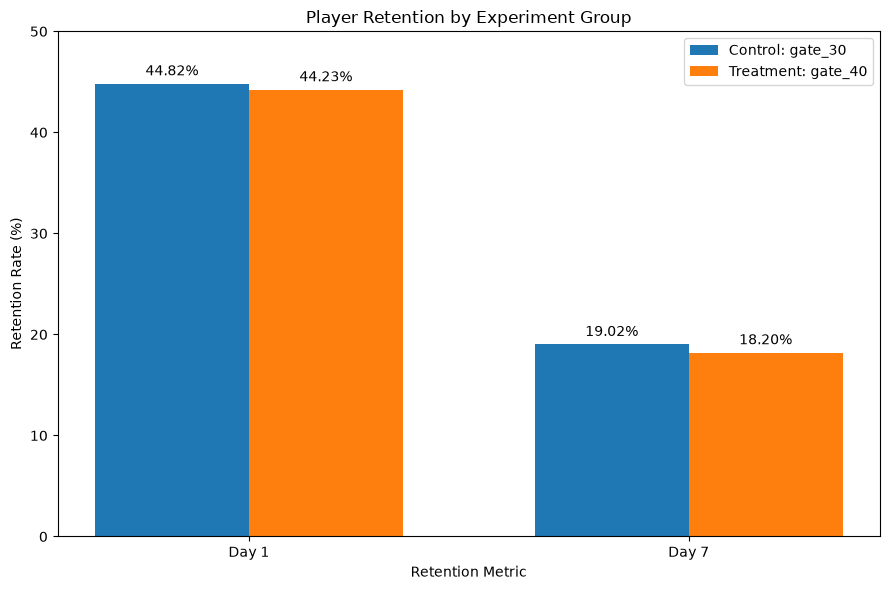

Chart saved to: E:\Analytics-Projects\cookie-cats-ab-testing-main\images\retention_comparison.png


In [22]:
metrics = ["Day 1", "Day 7"]

control_rates = [
    day_1_test["control_rate_pct"],
    day_7_test["control_rate_pct"]
]

treatment_rates = [
    day_1_test["treatment_rate_pct"],
    day_7_test["treatment_rate_pct"]
]

x_positions = np.arange(len(metrics))
bar_width = 0.35

plt.figure(figsize=(9, 6))

control_bars = plt.bar(
    x_positions - bar_width / 2,
    control_rates,
    bar_width,
    label="Control: gate_30"
)

treatment_bars = plt.bar(
    x_positions + bar_width / 2,
    treatment_rates,
    bar_width,
    label="Treatment: gate_40"
)

plt.title("Player Retention by Experiment Group")
plt.xlabel("Retention Metric")
plt.ylabel("Retention Rate (%)")
plt.xticks(x_positions, metrics)
plt.legend()
plt.ylim(0, 50)

for bars in [control_bars, treatment_bars]:
    for bar in bars:
        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.5,
            f"{height:.2f}%",
            ha="center",
            va="bottom"
        )

plt.tight_layout()

retention_chart_path = (
    project_root / "images" / "retention_comparison.png"
)

plt.savefig(
    retention_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved to: {retention_chart_path}")

In [23]:
rounds_99th_percentile = engagement_df[
    "sum_gamerounds"
].quantile(0.99)

print(
    f"99th percentile of game rounds: "
    f"{rounds_99th_percentile:.0f}"
)

99th percentile of game rounds: 493


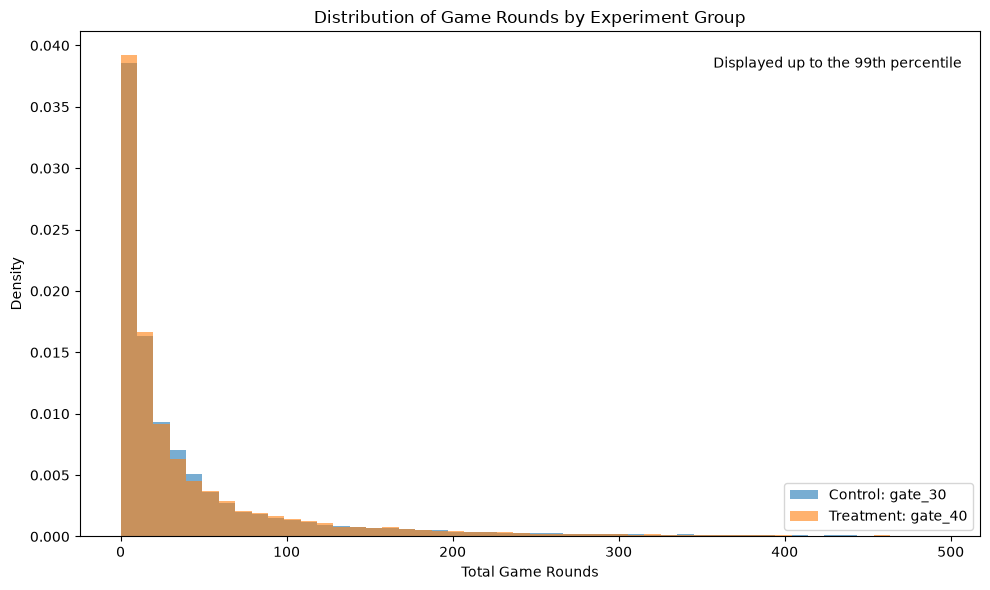

Chart saved to: E:\Analytics-Projects\cookie-cats-ab-testing-main\images\engagement_distribution.png


In [24]:
control_visual = control_rounds[
    control_rounds <= rounds_99th_percentile
]

treatment_visual = treatment_rounds[
    treatment_rounds <= rounds_99th_percentile
]

plt.figure(figsize=(10, 6))

plt.hist(
    control_visual,
    bins=50,
    alpha=0.6,
    label="Control: gate_30",
    density=True
)

plt.hist(
    treatment_visual,
    bins=50,
    alpha=0.6,
    label="Treatment: gate_40",
    density=True
)

plt.title("Distribution of Game Rounds by Experiment Group")
plt.xlabel("Total Game Rounds")
plt.ylabel("Density")
plt.legend()

plt.text(
    0.98,
    0.95,
    "Displayed up to the 99th percentile",
    transform=plt.gca().transAxes,
    ha="right",
    va="top"
)

plt.tight_layout()

engagement_chart_path = (
    project_root / "images" / "engagement_distribution.png"
)

plt.savefig(
    engagement_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved to: {engagement_chart_path}")

## Parametric Bootstrap Confidence Intervals\n
\n
This is a **parametric bootstrap-style simulation** for binary retention. For each group, retained-user counts are simulated from a binomial distribution using the observed group size and retention rate. The fixed random seed makes the simulation reproducible.\n
\n
The effect is treatment retention minus control retention, in percentage points. A negative effect means lower observed retention in the gate_40 group.

In [25]:
def bootstrap_retention_effect(
    data,
    metric,
    simulations=10_000,
    random_seed=42
):
    """
    Bootstrap the treatment-minus-control retention difference.

    For binary outcomes, bootstrap retained-user counts follow a
    binomial distribution using the observed group retention rates.
    """

    rng = np.random.default_rng(random_seed)

    control_values = data.loc[
        data["version"] == "gate_30",
        metric
    ]

    treatment_values = data.loc[
        data["version"] == "gate_40",
        metric
    ]

    control_users = len(control_values)
    treatment_users = len(treatment_values)

    control_rate = control_values.mean()
    treatment_rate = treatment_values.mean()

    control_retained_samples = rng.binomial(
        n=control_users,
        p=control_rate,
        size=simulations
    )

    treatment_retained_samples = rng.binomial(
        n=treatment_users,
        p=treatment_rate,
        size=simulations
    )

    control_rate_samples = (
        control_retained_samples / control_users
    )

    treatment_rate_samples = (
        treatment_retained_samples / treatment_users
    )

    effect_samples_pp = (
        treatment_rate_samples - control_rate_samples
    ) * 100

    return effect_samples_pp

In [26]:
day_1_bootstrap = bootstrap_retention_effect(
    data=df, metric="retention_1_flag"
)
day_7_bootstrap = bootstrap_retention_effect(
    data=df, metric="retention_7_flag"
)

bootstrap_results = pd.DataFrame({
    "metric": ["Day 1 Retention", "Day 7 Retention"],
    "observed_effect_pp": [
        day_1_test["absolute_effect_pp"], day_7_test["absolute_effect_pp"]
    ],
    "bootstrap_mean_effect_pp": [
        day_1_bootstrap.mean(), day_7_bootstrap.mean()
    ],
    "ci_95_low_pp": [
        np.percentile(day_1_bootstrap, 2.5),
        np.percentile(day_7_bootstrap, 2.5)
    ],
    "ci_95_high_pp": [
        np.percentile(day_1_bootstrap, 97.5),
        np.percentile(day_7_bootstrap, 97.5)
    ],
    "share_bootstrap_effects_above_zero": [
        np.mean(day_1_bootstrap > 0), np.mean(day_7_bootstrap > 0)
    ]
})
bootstrap_results.round(4)


,metric,observed_effect_pp,bootstrap_mean_effect_pp,ci_95_low_pp,ci_95_high_pp,share_bootstrap_effects_above_zero
0,Day 1 Retention,-0.5905,-0.5928,-1.2522,0.0606,0.0347
1,Day 7 Retention,-0.8201,-0.8213,-1.3356,-0.3111,0.0008


In [27]:
for _, result in bootstrap_results.iterrows():
    share_above_zero = result["share_bootstrap_effects_above_zero"] * 100
    print(f"\\n{result['metric']}")
    print(f"Observed treatment effect: {result['observed_effect_pp']:.2f} percentage points")
    print(
        f"Parametric bootstrap 95% interval: "
        f"[{result['ci_95_low_pp']:.2f}, {result['ci_95_high_pp']:.2f}]"
    )
    print(f"Share of simulated effects above zero: {share_above_zero:.2f}%")


\nDay 1 Retention
Observed treatment effect: -0.59 percentage points
Parametric bootstrap 95% interval: [-1.25, 0.06]
Share of simulated effects above zero: 3.47%
\nDay 7 Retention
Observed treatment effect: -0.82 percentage points
Parametric bootstrap 95% interval: [-1.34, -0.31]
Share of simulated effects above zero: 0.08%


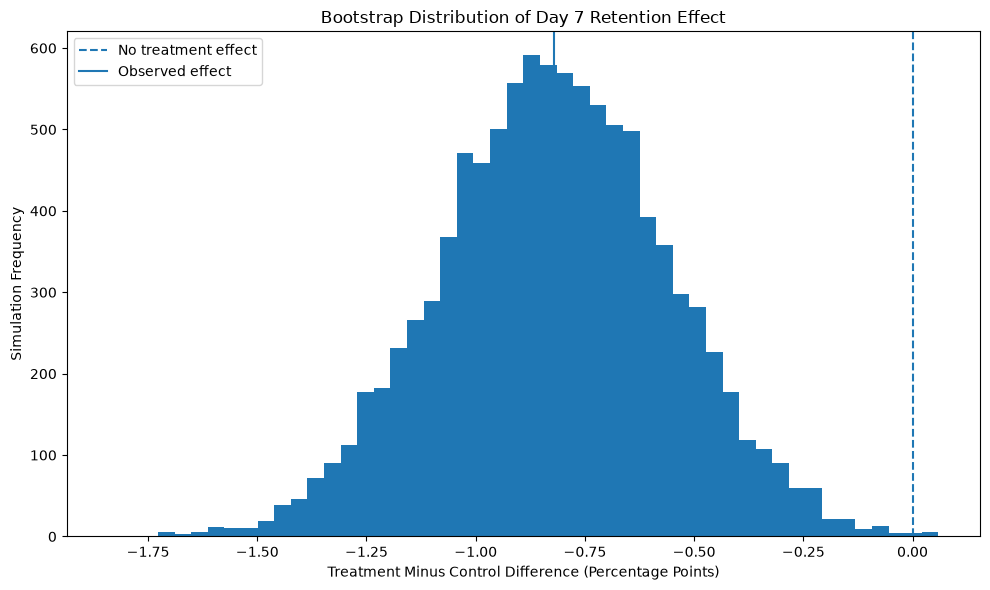

Chart saved to: E:\Analytics-Projects\cookie-cats-ab-testing-main\images\day_7_bootstrap_distribution.png


In [28]:
plt.figure(figsize=(10, 6))

plt.hist(
    day_7_bootstrap,
    bins=50
)

plt.axvline(
    0,
    linestyle="--",
    label="No treatment effect"
)

plt.axvline(
    day_7_test["absolute_effect_pp"],
    linestyle="-",
    label="Observed effect"
)

plt.title("Bootstrap Distribution of Day 7 Retention Effect")
plt.xlabel(
    "Treatment Minus Control Difference "
    "(Percentage Points)"
)
plt.ylabel("Simulation Frequency")
plt.legend()

plt.tight_layout()

bootstrap_chart_path = (
    project_root
    / "images"
    / "day_7_bootstrap_distribution.png"
)

plt.savefig(
    bootstrap_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved to: {bootstrap_chart_path}")

## Statistical Power and Minimum Detectable Effect\n
\n
The Minimum Detectable Effect (MDE) estimates the smallest difference detectable with 80% power at a two-sided 5% significance level, given the observed sample sizes and baseline retention rates. MDE is a planning threshold, not a boundary that proves an effect exists or does not exist. An observed effect smaller than the MDE may still be real, but is less reliably detected by this design.

In [29]:
from statsmodels.stats.power import NormalIndPower


power_model = NormalIndPower()

control_sample_size = (
    df.loc[df["version"] == "gate_30"].shape[0]
)

treatment_sample_size = (
    df.loc[df["version"] == "gate_40"].shape[0]
)

sample_size_ratio = (
    treatment_sample_size / control_sample_size
)

required_cohens_h = power_model.solve_power(
    effect_size=None,
    nobs1=control_sample_size,
    alpha=0.05,
    power=0.80,
    ratio=sample_size_ratio,
    alternative="two-sided"
)

print(f"Control sample size: {control_sample_size:,}")
print(f"Treatment sample size: {treatment_sample_size:,}")
print(f"Required Cohen's h: {required_cohens_h:.6f}")

Control sample size: 44,700
Treatment sample size: 45,489
Required Cohen's h: 0.018658


In [30]:
def calculate_retention_mde(
    baseline_rate,
    required_effect_size
):
    """
    Convert Cohen's h into upward and downward detectable
    retention differences around a baseline rate.
    """

    baseline_angle = np.arcsin(
        np.sqrt(baseline_rate)
    )

    detectable_rate_higher = np.sin(
        baseline_angle + required_effect_size / 2
    ) ** 2

    detectable_rate_lower = np.sin(
        baseline_angle - required_effect_size / 2
    ) ** 2

    upward_mde_pp = (
        detectable_rate_higher - baseline_rate
    ) * 100

    downward_mde_pp = (
        baseline_rate - detectable_rate_lower
    ) * 100

    return upward_mde_pp, downward_mde_pp

In [31]:
day_1_control_rate = (
    day_1_test["control_rate_pct"] / 100
)

day_7_control_rate = (
    day_7_test["control_rate_pct"] / 100
)

day_1_mde_up, day_1_mde_down = (
    calculate_retention_mde(
        day_1_control_rate,
        required_cohens_h
    )
)

day_7_mde_up, day_7_mde_down = (
    calculate_retention_mde(
        day_7_control_rate,
        required_cohens_h
    )
)

mde_results = pd.DataFrame({
    "metric": [
        "Day 1 Retention",
        "Day 7 Retention"
    ],
    "control_rate_pct": [
        day_1_test["control_rate_pct"],
        day_7_test["control_rate_pct"]
    ],
    "observed_effect_pp": [
        day_1_test["absolute_effect_pp"],
        day_7_test["absolute_effect_pp"]
    ],
    "detectable_increase_pp": [
        day_1_mde_up,
        day_7_mde_up
    ],
    "detectable_decrease_pp": [
        day_1_mde_down,
        day_7_mde_down
    ]
})

mde_results.round(4)

,metric,control_rate_pct,observed_effect_pp,detectable_increase_pp,detectable_decrease_pp
0,Day 1 Retention,44.8188,-0.5905,0.9287,0.9269
1,Day 7 Retention,19.0201,-0.8201,0.7376,0.7268


In [32]:
print("Day 1 observed effect:", f"{day_1_test['absolute_effect_pp']:.2f} pp")
print("Day 1 detectable decrease:", f"{day_1_mde_down:.2f} pp")
print(
    "Interpretation: the Day 1 decline is below the approximate detectable-decrease "
    "threshold; its non-significant result is inconclusive, not evidence of no effect."
)
print("\\nDay 7 observed effect:", f"{day_7_test['absolute_effect_pp']:.2f} pp")
print("Day 7 detectable decrease:", f"{day_7_mde_down:.2f} pp")
print(
    "Interpretation: the Day 7 decline exceeds the approximate detectable-decrease "
    "threshold and is statistically significant in the two-proportion test. Interpret "
    "cautiously because of the SRM warning."
)


Day 1 observed effect: -0.59 pp
Day 1 detectable decrease: 0.93 pp
Interpretation: the Day 1 decline is below the approximate detectable-decrease threshold; its non-significant result is inconclusive, not evidence of no effect.
\nDay 7 observed effect: -0.82 pp
Day 7 detectable decrease: 0.73 pp
Interpretation: the Day 7 decline exceeds the approximate detectable-decrease threshold and is statistically significant in the two-proportion test. Interpret cautiously because of the SRM warning.


In [33]:
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)


# Rename overlapping confidence-interval columns clearly
ztest_export = retention_test_results.rename(
    columns={
        "ci_95_low_pp": "ztest_ci_95_low_pp",
        "ci_95_high_pp": "ztest_ci_95_high_pp"
    }
)

bootstrap_export = bootstrap_results.rename(
    columns={
        "ci_95_low_pp": "bootstrap_ci_95_low_pp",
        "ci_95_high_pp": "bootstrap_ci_95_high_pp",
        "share_bootstrap_effects_above_zero":
            "share_bootstrap_effects_above_zero"
    }
)


retention_export = (
    ztest_export
    .merge(
        bootstrap_export[
            [
                "metric",
                "bootstrap_mean_effect_pp",
                "bootstrap_ci_95_low_pp",
                "bootstrap_ci_95_high_pp",
                "share_bootstrap_effects_above_zero"
            ]
        ],
        on="metric",
        how="left"
    )
    .merge(
        mde_results[
            [
                "metric",
                "detectable_increase_pp",
                "detectable_decrease_pp"
            ]
        ],
        on="metric",
        how="left"
    )
)


retention_export["metric_priority"] = np.where(
    retention_export["metric"] == "Day 7 Retention",
    "Primary",
    "Secondary"
)

retention_export["statistically_significant"] = (
    retention_export["p_value"] < 0.05
)


def create_retention_decision(row):
    if row["p_value"] >= 0.05:
        return "Inconclusive at 5% significance"

    if row["absolute_effect_pp"] > 0:
        return "Treatment significantly better"

    return "Treatment significantly worse"


retention_export["statistical_decision"] = (
    retention_export.apply(
        create_retention_decision,
        axis=1
    )
)


retention_export_path = (
    processed_dir / "retention_statistical_summary.csv"
)

retention_export.to_csv(
    retention_export_path,
    index=False
)

retention_export.round(4)

,metric,control_users,treatment_users,control_retained,treatment_retained,control_rate_pct,treatment_rate_pct,absolute_effect_pp,ztest_ci_95_low_pp,ztest_ci_95_high_pp,...,p_value,bootstrap_mean_effect_pp,bootstrap_ci_95_low_pp,bootstrap_ci_95_high_pp,share_bootstrap_effects_above_zero,detectable_increase_pp,detectable_decrease_pp,metric_priority,statistically_significant,statistical_decision
0,Day 1 Retention,44700,45489,20034,20119,44.8188,44.2283,-0.5905,-1.2392,0.0582,...,0.0744,-0.5928,-1.2522,0.0606,0.0347,0.9287,0.9269,Secondary,False,Inconclusive at 5% significance
1,Day 7 Retention,44700,45489,8502,8279,19.0201,18.2000,-0.8201,-1.3282,-0.3121,...,0.0016,-0.8213,-1.3356,-0.3111,0.0008,0.7376,0.7268,Primary,True,Treatment significantly worse


In [34]:
engagement_test_export = pd.DataFrame({
    "metric": ["Total Game Rounds"],
    "control_mean_rounds": [control_rounds.mean()],
    "treatment_mean_rounds": [treatment_rounds.mean()],
    "mean_difference": [mean_difference],
    "control_median_rounds": [control_rounds.median()],
    "treatment_median_rounds": [treatment_rounds.median()],
    "median_difference": [median_difference],
    "mann_whitney_u_statistic": [u_statistic],
    "p_value": [engagement_p_value],
    "rank_biserial_effect_size": [rank_biserial_effect],
    "statistically_significant": [engagement_p_value < 0.05],
    "practical_effect": [
        "Negligible" if abs(rank_biserial_effect) < 0.10
        else "Potentially meaningful"
    ],
    "extreme_records_excluded": [int(df["is_extreme_outlier"].sum())],
    "zero_round_players_included": [True],
})
engagement_test_path = processed_dir / "engagement_statistical_summary.csv"
engagement_test_export.to_csv(engagement_test_path, index=False)
engagement_test_export.round(6)


,metric,control_mean_rounds,treatment_mean_rounds,mean_difference,control_median_rounds,treatment_median_rounds,median_difference,mann_whitney_u_statistic,p_value,rank_biserial_effect_size,statistically_significant,practical_effect,extreme_records_excluded,zero_round_players_included
0,Total Game Rounds,51.342111,51.298776,-0.043335,17.0,16.0,-1.0,1.009027e+09,0.050892,-0.007504,False,Negligible,1,True


In [35]:
allocation_export = allocation_summary.copy()

allocation_export["expected_percentage"] = 50.0
allocation_export["srm_p_value"] = srm_p_value
allocation_export["srm_status"] = np.where(
    srm_p_value < 0.05,
    "SRM warning under assumed 50/50 allocation",
    "No SRM detected"
)

allocation_export_path = (
    processed_dir / "sample_allocation_summary.csv"
)

allocation_export.to_csv(
    allocation_export_path,
    index=False
)

allocation_export.round(4)

,version,observed_players,expected_players,observed_percentage,expected_percentage,srm_p_value,srm_status
0,gate_30,44700,45094.5,49.5626,50.0,0.0086,SRM warning under assumed 50/50 allocation
1,gate_40,45489,45094.5,50.4374,50.0,0.0086,SRM warning under assumed 50/50 allocation


In [36]:
for file_path in sorted(processed_dir.glob("*.csv")):
    print(file_path.name)

engagement_statistical_summary.csv
retention_statistical_summary.csv
sample_allocation_summary.csv
